# **Gradient Descent**

In [55]:
from sklearn.datasets import make_regression
import numpy as np

In [56]:
x,y = make_regression(n_samples=4,n_features=1,n_informative=1,n_targets=1,noise=80,random_state=13)

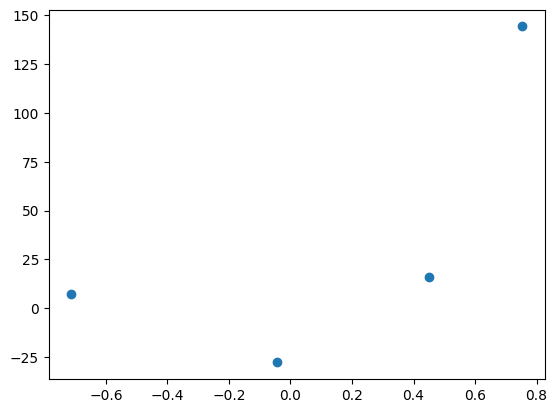

In [57]:
import matplotlib.pyplot as plt
plt.scatter(x,y)

In [58]:
# apply ols
from sklearn.linear_model import LinearRegression

In [59]:
reg = LinearRegression()
reg.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [60]:
LinearRegression(copy_X=True,fit_intercept=True,n_jobs=None)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [61]:
reg.coef_,reg.intercept_

(array([78.35063668]), np.float64(26.15963284313262))

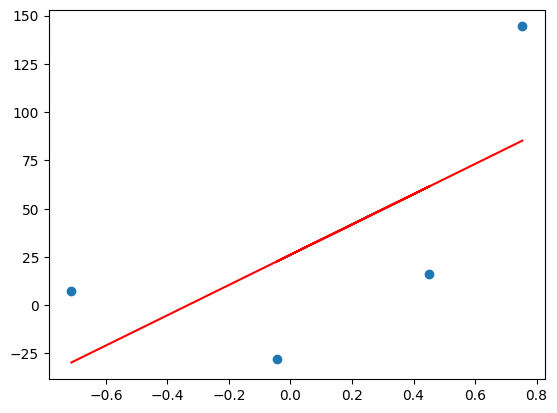

In [62]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color = 'red')

In [63]:
# applying gradient descent assuming slope is constant m = 78.35
# and let's assume the starting value for intercept b = 0
y_pred = ((78.35*x)+ 0).reshape(4)

In [64]:
y_pred

array([-55.81580837,  35.39949674,  -3.48681619,  59.05759577])

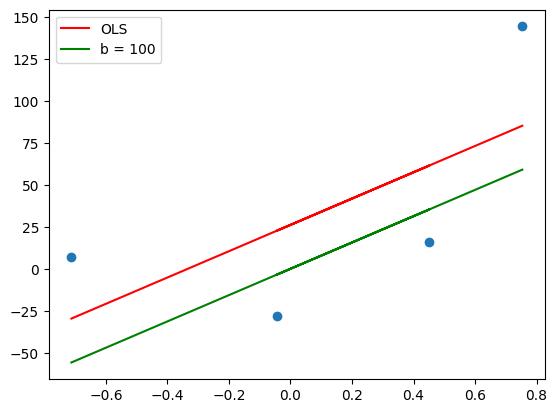

In [65]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color = 'red',label = "OLS")
plt.plot(x,y_pred,color = 'green',label = 'b = 100')
plt.legend()
plt.show()

In [66]:
m = 78.35
b= 100
loss_slope = -2*np.sum(y-m*x.ravel() - b)
loss_slope

np.float64(590.7223659179078)

In [67]:
# lets learning_rate = 0.1
lr = 0.1
step_size = loss_slope*lr
step_size 

np.float64(59.072236591790784)

In [68]:
# calulating the new intercept
b = b - step_size
b

np.float64(40.927763408209216)

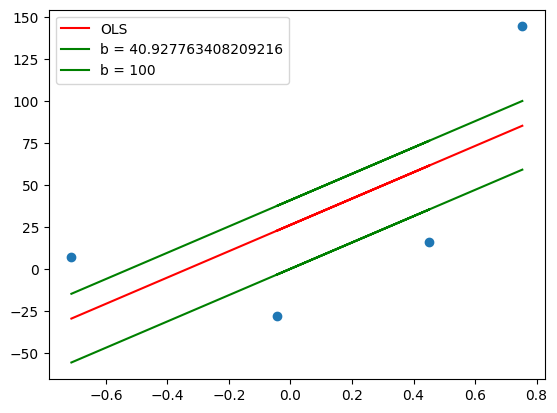

In [69]:
y_pred1 = ((78.35 * x ) + b).reshape(4)
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color = 'red',label = 'OLS')
plt.plot(x,y_pred1,color = 'green',label = f'b = {b}')
plt.plot(x,y_pred,color = 'green',label = 'b = 100')
plt.legend()

In [70]:
# iteration 2
loss_slope = -2* np.sum(y-m*x.ravel() - b)
loss_slope

np.float64(118.14447318358157)

In [71]:
step_size = loss_slope*lr
step_size

np.float64(11.814447318358157)

In [72]:
b = b - step_size
b

np.float64(29.11331608985106)

In [73]:
y_pred2 = ((78.35* x)+b).reshape(4)
y_pred2

array([-26.70249228,  64.51281283,  25.6264999 ,  88.17091186])

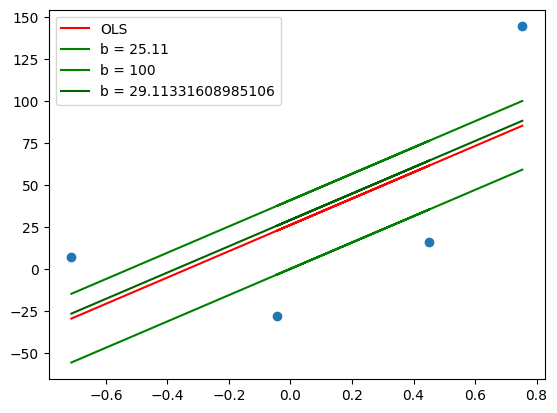

In [74]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color = 'red',label = 'OLS')
plt.plot(x,y_pred1,color = 'green',label = f'b = 25.11')
plt.plot(x,y_pred,color = 'green',label = 'b = 100')
plt.plot(x,y_pred2,color = 'darkgreen',label = f'b = {b}')
plt.legend()

In [75]:
# iteration 3
loss_slope  = - 2 * np.sum(y- m*x.ravel()-b)
loss_slope

np.float64(23.62889463671634)

In [76]:
step_size = loss_slope*lr
step_size

np.float64(2.362889463671634)

In [77]:
b = b - step_size
b

np.float64(26.750426626179426)

In [78]:
y_pred3 = ((78.35* x)+b).reshape(4)
y_pred3

array([-29.06538175,  62.14992337,  23.26361044,  85.80802239])

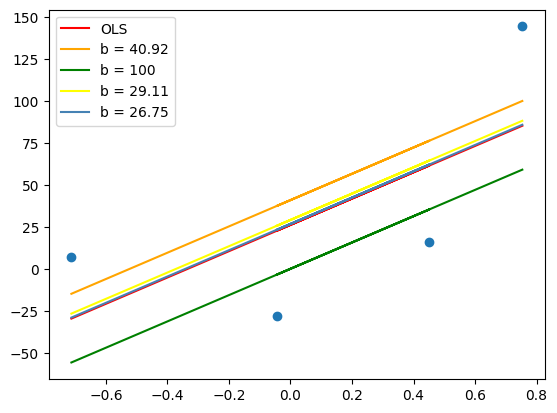

In [79]:
plt.scatter(x,y)
plt.plot(x,reg.predict(x),color = 'red',label = 'OLS')
plt.plot(x,y_pred1,color = 'orange',label = f'b = 40.92')
plt.plot(x,y_pred,color = 'green',label = 'b = 100')
plt.plot(x,y_pred2,color = 'yellow',label = f'b = 29.11')
plt.plot(x,y_pred3,color = 'steelblue',label = f'b = {b:.2f}')
plt.legend()

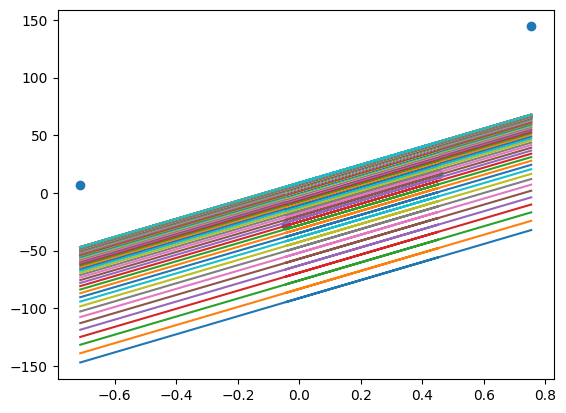

In [83]:
b = -100
m = 78.35
lr = 0.01
epochs = 100
for i in range(epochs):
    loss_slope = -2 * np.sum(m*x.ravel()- b)
    b = b - (lr*loss_slope)
    y_pred = m*x+b
    plt.plot(x,y_pred)
plt.scatter(x,y)